# Wildfire prediction → expected incident radiant heat

This notebook demonstrates the integrated `wildfire.heat` module in the unified package. It loads an existing trained wildfire predictor, reads aligned ecological fuel data, and produces spatial matrices of **incident radiant heat flux** in **W/m²** and **incident radiant energy per unit area** in **J/m²**.

The real example is **Fish Creek, Wyoming**, at cutoff **2024-08-23 00:00 UTC**, with a one-hour forecast interval. The active checkpoint is `wildfire.paths.DEFAULT_CHECKPOINT`, the supported 5×5 model retained in the completed `20261010_categorical_balanced_benchmark` run. Stored notebook outputs are historical results from their recorded weights. Run the cells from top to bottom to produce outputs from the current default; there is no training or data download.

**API output:** standard heat prediction methods return `(prediction_matrix, coordinates_matrix)`, with shapes `(H, W)` and `(H, W, 2)`. Coordinates are `(latitude, longitude)` in degrees, EPSG:4326, at receiver cell centers. Pass the grid's projected EPSG code in metres to the heat model, or use a sample containing `epsg` and `affine_transform`. This notebook uses the explicit `*_details` methods when it needs dose, bounds, source coverage, and provenance. Local synthetic grids have no geographic CRS and use details methods. The saved outputs below are from the original physical demonstration; rerun the cells to execute the updated tuple interface.

**Run environment:** select this workspace's `.venv` Python 3.12 interpreter as the notebook kernel. The existing environment contains PyTorch, Rasterio, Matplotlib, NumPy, Pandas, IPython, and ipykernel. The first code cell prints the actual interpreter and checks the imported package location. A kernel named `.venv` from another project is not sufficient.

**Scope:** the example estimates radiation from *newly igniting cells*. Cumulative burned area does not identify currently active fire, so ongoing combustion of already-burned cells is not inferred. Combustion parameters are illustrative. This is a reproducible model demonstration, not calibration against measured wildfire heat or validation of operational forecast skill.

In [1]:
from pathlib import Path
import os
import sys
import tempfile

# Locate the workspace when launched from its root or any subfolder.
WORKSPACE = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'pyproject.toml').is_file()
     and (p / 'wildfire').is_dir()),
    None,
)
if WORKSPACE is None:
    raise RuntimeError("Open this notebook from the wildfire workspace or set WORKSPACE explicitly.")
sys.path.insert(0, str(WORKSPACE))
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "expected_heat_notebook_matplotlib"))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
import wildfire.heat as heat_module
from wildfire.heat import AffineGrid
from wildfire.heat import CombustionParameters
from wildfire.heat import EcologicalFuelMaps
from wildfire.heat import ExpectedHeatFluxModel
from wildfire.heat import WildfireHeatModel
from wildfire.data import WildfireSequenceDataset

assert Path(heat_module.__file__).resolve() == WORKSPACE / 'wildfire' / 'heat.py'
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| PyTorch:", torch.__version__)
print("Workspace:", WORKSPACE)
print("Imported heat package:", heat_module.__file__)
print("Accelerators available — MPS:", torch.backends.mps.is_available(), "CUDA:", torch.cuda.is_available())

Matplotlib is building the font cache; this may take a moment.


Interpreter: /Users/movinggk/Documents/영재멘토/WildfireGuardian/.venv/bin/python
Python: 3.12.13 | NumPy: 1.26.4 | PyTorch: 2.5.1
Workspace: /Users/movinggk/Documents/영재멘토/WildfireGuardian
Imported heat package: /Users/movinggk/Documents/영재멘토/WildfireGuardian/expected_heat_flux/__init__.py
Accelerators available — MPS: True CUDA: False


## 1. Select the event, checkpoint, and physical assumptions

These variables are editable. `DEVICE="cpu"` makes the default example portable. The checkpoint predicts **new cumulative burning within the next exact hour**, so `INTERVAL_S` must remain 3600 for this trained model.

All physical values below are explicit assumptions rather than inferred combustion measurements. The 10 kg/m² fuel fallback applies to the **unmapped portion of a cell**, or the whole cell when its reference loading/coverage cannot be read. The consumed fraction applies to the full-cell dry-fuel loading, including any fallback contribution.

In [2]:
DATA_ROOT = WORKSPACE / "data" / "environment"
from wildfire.paths import DEFAULT_CHECKPOINT
CHECKPOINT = DEFAULT_CHECKPOINT
EVENT = "WY-BTF-002416_FishCreek"
CUTOFF_UTC = "2024-08-23T00:00:00Z"
DEVICE = "cpu"
INTERVAL_S = 3600.0
HEAT_OF_COMBUSTION_J_KG = 18_000_000.0
BURNING_DURATION_S = 300.0
CONSUMED_FRACTION = 0.10
UNMAPPED_FUEL_FALLBACK_KG_M2 = 10.0
RADIATIVE_FRACTION = 0.30
EMISSION_HEIGHT_M = 5.0
RECEIVER_HEIGHT_M = 0.0
ATMOSPHERIC_TRANSMISSIVITY = 1.0
import tempfile
OUTPUT_ROOT = WORKSPACE / "demonstration" / "heat" / "notebook_runs"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = Path(tempfile.mkdtemp(prefix="unsigned-", dir=OUTPUT_ROOT))

if not CHECKPOINT.is_file():
    raise FileNotFoundError(f"Saved checkpoint not found: {CHECKPOINT}")
parameters = {
    "Forecast interval (s)": INTERVAL_S,
    "Effective combustion heat (J/kg)": HEAT_OF_COMBUSTION_J_KG,
    "Active-emission duration (s)": BURNING_DURATION_S,
    "Consumed dry-mass fraction": CONSUMED_FRACTION,
    "Unmapped fuel fallback (kg/m²)": UNMAPPED_FUEL_FALLBACK_KG_M2,
    "Radiative fraction": RADIATIVE_FRACTION,
    "Source emitter elevation (m)": EMISSION_HEIGHT_M,
    "Horizontal receiver elevation (m)": RECEIVER_HEIGHT_M,
    "Atmospheric transmissivity": ATMOSPHERIC_TRANSMISSIVITY,
}
display(pd.DataFrame(parameters.items(), columns=["Assumption", "Value"]))

,Assumption,Value
0,Forecast interval (s),3600.0
1,Effective combustion heat (J/kg),18000000.0
2,Active-emission duration (s),300.0
3,Consumed dry-mass fraction,0.1
4,Unmapped fuel fallback (kg/m²),10.0
5,Radiative fraction,0.3
6,Source emitter elevation (m),5.0
7,Horizontal receiver elevation (m),0.0
8,Atmospheric transmissivity,1.0


## 2. Define what the heat model computes

For cell $i$, let $w_i$ be dry fuel load (kg/m²), $f_i$ consumed fraction, $H_{c,i}$ effective heat of combustion (J/kg), and $T_i>0$ the active-emission duration (s). The prescribed heat-release-rate density conditional on active burning is

$$s_i=\frac{w_i f_i H_{c,i}}{T_i}\quad[\mathrm{W/m^2}].$$

Let $\chi_i$ be radiative fraction, $\tau$ common atmospheric transmissivity, $D_i$ the cell's horizontal footprint, and $h=z_s-z_r>0$ emitter–receiver height separation. The dimensionless transfer factor at horizontal receiver coordinate $x$ is

$$K_i(x)=\frac{1}{4\pi}\int_{D_i}\frac{h}{(\lVert y-x\rVert^2+h^2)^{3/2}}\,dA_y
=\frac{\Omega_i(x)}{4\pi}.$$

The package evaluates the footprint's solid angle $\Omega_i$ exactly for its affine parallelogram geometry. It distributes isotropic emission uniformly over that elevated footprint. For active-burning probability $p_i(t)$,

$$\mathbb E[q''(x,t)]=\tau\sum_i p_i(t)\chi_i s_i K_i(x).$$

**Cell independence is unnecessary for this mean.** Receiver values are upward-facing horizontal **point samples at cell centers**, not receiver-cell area averages. Whole-cell source strength is averaged over the cell footprint; subcell flame location is unresolved. This geometry omits convection, tilted flames, terrain/smoke blocking, path-dependent transmission, and fire sources outside the supplied grid.

The energy conversion follows mass-loss rate times combustion heat ([NIST SP 1007, Eq. 1](https://tsapps.nist.gov/publication/get_pdf.cfm?pub_id=911301)); inverse-square spreading and receiver projection follow [NIST SP 1169, §6.1](https://nvlpubs.nist.gov/nistpubs/SpecialPublications/NIST.SP.1169.pdf). The footprint integration and constant burning profile are explicit modeling choices. See [the package README](../README.md#heat-guide) and [source records](../wildfire/heat_sources.json) for derivation, primary references, and limits.

### New-burning probability is converted to active-burning occupancy

The saved predictor returns $q_i=\mathbb P(\text{first new burning in cell }i\text{ within the next }\Delta\text{ seconds})$, with $\Delta=3600$ s. This differs from the original active-burning probability input to the radiation-only API.

The integration assumes conditional ignition time $A_i\mid\text{new burning}\sim\mathrm{Uniform}(0,\Delta)$, followed by constant active emission on $[A_i,A_i+T_i)$. Define $r_i=\min(T_i,\Delta)/\Delta$. Then

$$\bar p_i=\frac{1}{\Delta}\int_0^\Delta p_i(t)\,dt=q_i\left(r_i-\frac{r_i^2}{2}\right),
\qquad p_i(\Delta)=q_i r_i.$$

Thus **interval-mean flux**, **endpoint flux**, and **interval energy per area** are distinct:

$$\bar q''(x)=\tau\sum_i\bar p_i\chi_i s_iK_i(x),
\qquad E''(x)=\Delta\bar q''(x)\quad[\mathrm{J/m^2}].$$

The uniform conditional ignition-time distribution is an additional assumption; the endpoint predictor does not identify it.

In [3]:
r = min(BURNING_DURATION_S, INTERVAL_S) / INTERVAL_S
print(f"For the selected duration, mean active probability = q × {r - r*r/2:.9f}")
print(f"Endpoint active probability = q × {r:.9f}")

For the selected duration, mean active probability = q × 0.079861111
Endpoint active probability = q × 0.083333333


## 3. Load one cutoff snapshot using the saved channel contract

The checkpoint determines channel order, categorical vocabulary, and training-fitted normalization. No preprocessing is fitted on this demonstration event. The loader is configured to expose only one cutoff snapshot and uses completed-day daily inputs.

**Retrospective-data limitation:** the current cumulative burned state and its coverage are reconstructed from the event's retrospective arrival-time/final-extent data. Checking environmental timestamps and excluding explicit future-label tensors does not establish that every input was available in a live deployment.

In [4]:
saved = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
contract = saved["contract"]
checkpoint_best_epoch = int(saved["best_epoch"])
del saved

dataset = WildfireSequenceDataset(
    DATA_ROOT,
    events=[EVENT],
    channels=contract["channels"],
    categorical_encoding=contract.get("categorical_encoding", "one_hot"),
    categorical_classes=contract.get("categorical_classes") or None,
    sequence_length=1,
    time_range=(CUTOFF_UTC, CUTOFF_UTC),
    daily_policy="completed_day",
)
try:
    assert len(dataset) == 1, "The demonstration requires one full-grid cutoff snapshot."
    sample = dataset[0]
finally:
    dataset.close()

grid = AffineGrid(tuple(float(v) for v in sample["affine_transform"].tolist()))
shape = tuple(sample["burned_area"].shape[-2:])
cutoff_seconds = int(sample["time_utc"][0])
source_interval_ends = sample["source_interval_end_utc"][0].numpy()
assert np.all((source_interval_ends < 0) | (source_interval_ends <= cutoff_seconds))
current_burned = sample["burned_area"][0, 0].numpy()
current_burned_valid = sample["burned_area_valid"][0, 0].numpy()

print("Event:", EVENT, "| Cutoff:", CUTOFF_UTC)
print("Architecture:", contract["architecture"], "| Best saved epoch:", checkpoint_best_epoch)
print("Spatial matrix shape:", shape, "| EPSG:", int(sample["epsg"]))
print("Metric affine transform:", grid.transform, "| Source cell area (m²):", grid.cell_area_m2)
print("Saved feature channels:", len(contract["channels"]))
display(pd.DataFrame({"Channel": contract["channels"]}))

Event: WY-BTF-002416_FishCreek | Cutoff: 2024-08-23T00:00:00Z
Architecture: EnvironmentConditionedConvolution | Best saved epoch: 8
Spatial matrix shape: (103, 73) | EPSG: 5070
Metric affine transform: (375.0, 0.0, -1141125.0, 0.0, -375.0, 2393250.0) | Source cell area (m²): 140625.0
Saved feature channels: 19


,Channel
0,weather.temperature_2m
1,weather.wind_eastward_10m
2,weather.wind_northward_10m
3,terrain.slope_degrees
4,vegetation.tree_cover_percent
5,biome.biome_class=1
6,biome.biome_class=2
7,biome.biome_class=3
8,biome.biome_class=4
9,biome.biome_class=5


## 4. Load ecological dry-fuel reference maps

The U.S. event bundle contains aligned LANDFIRE FCCS reference fuel loading and lookup coverage. The reader verifies raster/grid alignment and converts **U.S. short tons per acre** to **kg/m²** using $1\text{ short ton/ac}=0.2241702312388912\text{ kg/m²}$.

For readable cells, mapped coverage fraction $c_i\in[0,1]$ and mapped-part mean loading $w_i^{\mathrm{mapped}}$ give the explicitly assumed whole-cell loading

$$w_i=c_iw_i^{\mathrm{mapped}}+(1-c_i)w_i^{\mathrm{fallback}}.$$

`ecology.valid` identifies cells with complete lookup coverage; it is preserved even after the fallback creates a usable source-strength map. Reference fuelbeds span multiple fuel strata and do not measure event-date consumed mass. The explicit consumed fraction is therefore still required. No universal conversion from biome/tree cover to dry-fuel mass or moisture damping is applied. See [LANDFIRE FCCS](https://www.landfire.gov/fuel/fccs) and [FCCS technical documentation](https://research.fs.usda.gov/treesearch/45283).

In [5]:
fuel_dir = DATA_ROOT / "regions" / EVENT / "fuel"
fuel_loading_path = fuel_dir / "total_available_fuel_loading_tons_per_acre_375m.tif"
fuel_coverage_path = fuel_dir / "fuel_loading_lookup_coverage_fraction_375m.tif"
ecology = EcologicalFuelMaps.from_fccs_rasters(
    fuel_loading_path, fuel_coverage_path, grid=grid, expected_shape=shape,
)
combustion = ecology.combustion_parameters(
    heat_of_combustion_j_kg=HEAT_OF_COMBUSTION_J_KG,
    burning_duration_s=BURNING_DURATION_S,
    consumed_fraction=CONSUMED_FRACTION,
    fallback_fuel_load_kg_m2=UNMAPPED_FUEL_FALLBACK_KG_M2,
)
fuel_load = np.asarray(combustion.fuel_load_kg_m2)
assert fuel_load.shape == shape and np.all(np.isfinite(fuel_load))
print("Fully covered fuel cells:", int(ecology.valid.sum()), "/", fuel_load.size)
print("Mean lookup coverage fraction:", float(np.nanmean(ecology.coverage_fraction)))
print("Whole-cell fuel load with explicit fallback (kg/m²), min/max:", float(fuel_load.min()), float(fuel_load.max()))

Fully covered fuel cells: 6016 / 7519
Mean lookup coverage fraction: 0.9766817931994977
Whole-cell fuel load with explicit fallback (kg/m²), min/max: 0.6686554482957516 26.209957371736163


## 5. Predict the spatial heat matrices

Only the six explicitly listed cutoff input keys are passed to prediction. Loader fields such as `newly_burned_area`, `arrival_hours`, and `arrival_std_hours` are excluded. Known already-burned cells cannot have a first-new-burning event during the next hour, so their new-burning probability is structurally zero. This does not imply zero present combustion.

The model retains unknown source probabilities. Because radiation is nonlocal, even a receiver whose own cell has known probability can receive radiation from an unknown source cell elsewhere.

In [6]:
heat_model = WildfireHeatModel.from_checkpoint(
    CHECKPOINT,
    grid=grid,
    combustion=combustion,
    radiative_fraction=RADIATIVE_FRACTION,
    emission_height_m=EMISSION_HEIGHT_M,
    receiver_height_m=RECEIVER_HEIGHT_M,
    atmospheric_transmissivity=ATMOSPHERIC_TRANSMISSIVITY,
    interval_s=INTERVAL_S,
    epsg=int(sample["epsg"]),
    device=DEVICE,
)
inference_keys = (
    "burned_area", "features", "channel_names",
    "burned_area_valid", "feature_valid", "affine_transform", "epsg",
)
inference_sample = {key: sample[key] for key in inference_keys}
result = heat_model.predict_sample_details(inference_sample)

# The default API returns the heat matrix and receiver coordinates.
# Reuse the computed probabilities to avoid a second predictor invocation.
expected_heat_matrix, coordinates_latlon_deg = heat_model.predict_from_new_burn_probability(
    result.new_burn_probability, probability_valid=result.probability_valid,
)
np.testing.assert_allclose(expected_heat_matrix, result.expected_heat_flux_w_m2, equal_nan=True)

# Main user-facing spatial matrices; every matrix has shape (rows, columns).
expected_heat_spatial_matrix = result.expected_heat_flux_w_m2
known_source_heat_spatial_matrix = result.known_source_heat_flux_w_m2
heat_lower_bound = result.heat_flux_lower_bound_w_m2
heat_upper_bound = result.heat_flux_upper_bound_w_m2
expected_incident_energy_spatial_matrix = result.expected_incident_energy_j_m2

print("Prediction inputs:", inference_keys)
print("Known new-burning probabilities:", int(result.probability_valid.sum()))
print("Unknown new-burning probabilities:", int((~result.probability_valid).sum()))
print("Full expected heat matrix identified:", result.complete)

Prediction inputs: ('burned_area', 'features', 'channel_names', 'burned_area_valid', 'feature_valid', 'affine_transform', 'epsg')
Known new-burning probabilities: 1246
Unknown new-burning probabilities: 6273
Full expected heat matrix identified: False


### Read the output names precisely

| Matrix | Meaning | Units |
| --- | --- | --- |
| `result.new_burn_probability` | New-burning event probability over the next hour; unknown cells remain `NaN` | dimensionless |
| `result.mean_active_burning_probability` | Time-mean active occupancy of those new ignitions | dimensionless |
| `expected_heat_spatial_matrix` | Full supplied-domain interval-mean expected radiant flux, only identified if unresolved sources cannot contribute | W/m² |
| `known_source_heat_spatial_matrix` | Expected contribution from known source probabilities; equals the lower bound here | W/m² |
| `heat_lower_bound`, `heat_upper_bound` | Mathematical bounds allowing unknown event probabilities to vary in `[0,1]` | W/m² |
| `expected_incident_energy_spatial_matrix` | Full supplied-domain expected incident radiant energy over the hour | J/m² |
| `result.incident_energy_lower_bound_j_m2`, `result.incident_energy_upper_bound_j_m2` | Corresponding energy bounds | J/m² |

For this real event, the canonical full expected flux and energy matrices are entirely `NaN`: unresolved emitting sources can contribute at every receiver. The finite known-source field is still useful, but it is not the full expected field. Neither bound assigns an observed probability to a missing cell. The bounds condition on the supplied combustion, uniform ignition-time assumption, geometry, and source domain; they do not bound physical model error, convection, or external fires.

In [7]:
def matrix_statistics(matrix):
    values = np.asarray(matrix)
    finite = values[np.isfinite(values)]
    return {
        "rows": values.shape[0], "columns": values.shape[1],
        "finite cells": int(finite.size), "unknown cells": int(values.size - finite.size),
        "minimum": float(finite.min()) if finite.size else None,
        "maximum": float(finite.max()) if finite.size else None,
    }

matrices = {
    "Full expected mean flux (W/m²)": expected_heat_spatial_matrix,
    "Known-source mean flux / lower bound (W/m²)": known_source_heat_spatial_matrix,
    "Upper bound on mean flux (W/m²)": heat_upper_bound,
    "Full expected interval energy (J/m²)": expected_incident_energy_spatial_matrix,
    "Lower bound on interval energy (J/m²)": result.incident_energy_lower_bound_j_m2,
    "Upper bound on interval energy (J/m²)": result.incident_energy_upper_bound_j_m2,
}
display(pd.DataFrame({name: matrix_statistics(value) for name, value in matrices.items()}).T)

assert expected_heat_spatial_matrix.shape == shape
assert np.all(np.isnan(result.new_burn_probability[~result.probability_valid]))
known_q = result.new_burn_probability[result.probability_valid]
assert np.all((known_q >= 0) & (known_q <= 1))
assert np.all(heat_lower_bound <= heat_upper_bound + 1e-9)
np.testing.assert_allclose(known_source_heat_spatial_matrix, heat_lower_bound)
np.testing.assert_allclose(result.incident_energy_lower_bound_j_m2, heat_lower_bound * INTERVAL_S)
np.testing.assert_allclose(result.incident_energy_upper_bound_j_m2, heat_upper_bound * INTERVAL_S)
if not result.complete:
    assert np.isnan(expected_heat_spatial_matrix).all()
    assert np.isnan(expected_incident_energy_spatial_matrix).all()
print("Probability, shape, missingness, bounds, and flux-to-energy checks passed.")

,rows,columns,finite cells,unknown cells,minimum,maximum
Full expected mean flux (W/m²),103.0,73.0,0.0,7519.0,NaN,NaN
Known-source mean flux / lower bound (W/m²),103.0,73.0,7519.0,0.0,0.000005,1.561772e+02
Upper bound on mean flux (W/m²),103.0,73.0,7519.0,0.0,0.683458,1.878940e+03
Full expected interval energy (J/m²),103.0,73.0,0.0,7519.0,NaN,NaN
Lower bound on interval energy (J/m²),103.0,73.0,7519.0,0.0,0.017700,5.622381e+05
Upper bound on interval energy (J/m²),103.0,73.0,7519.0,0.0,2460.447021,6.764183e+06


Probability, shape, missingness, bounds, and flux-to-energy checks passed.


## 6. Inspect the spatial maps

Gray probability cells are unknown. The figures use the projected source grid in kilometres relative to its upper-left corner. The first figure shows the full grid; the second magnifies the current-fire neighbourhood for visibility. **Only the display is cropped:** all heat contributions are computed on the original full source grid.

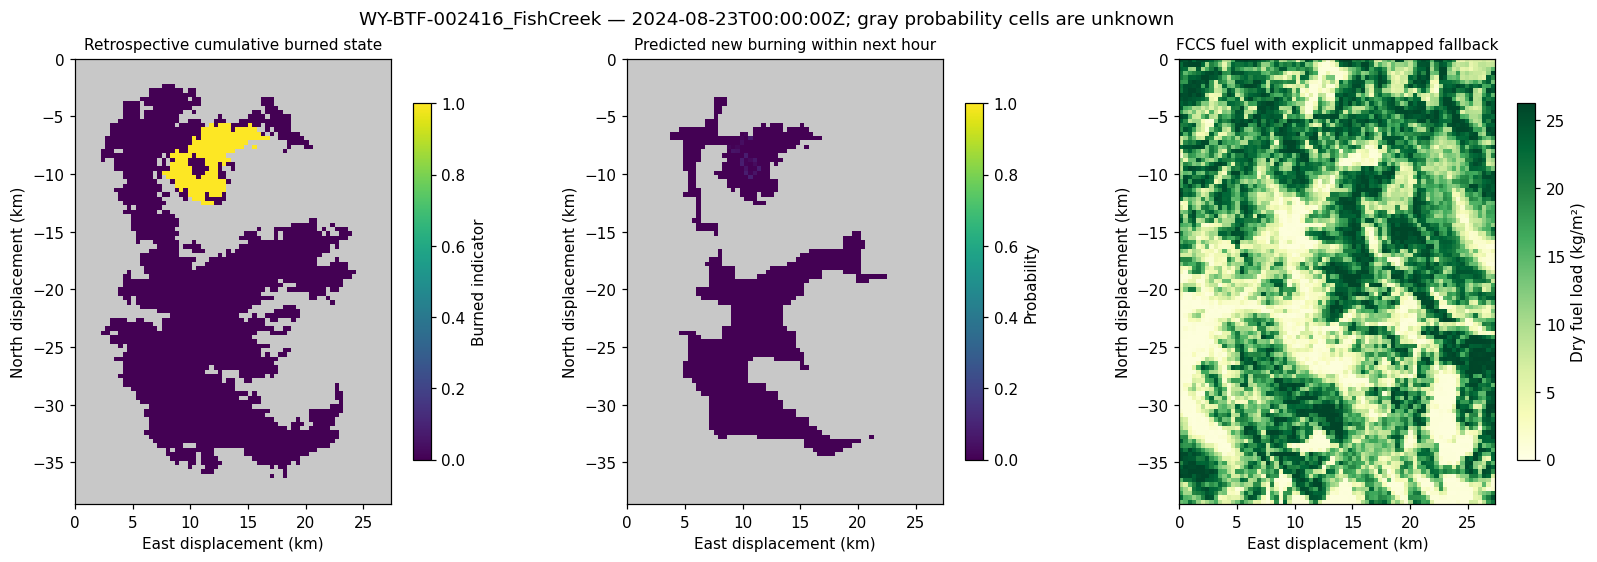

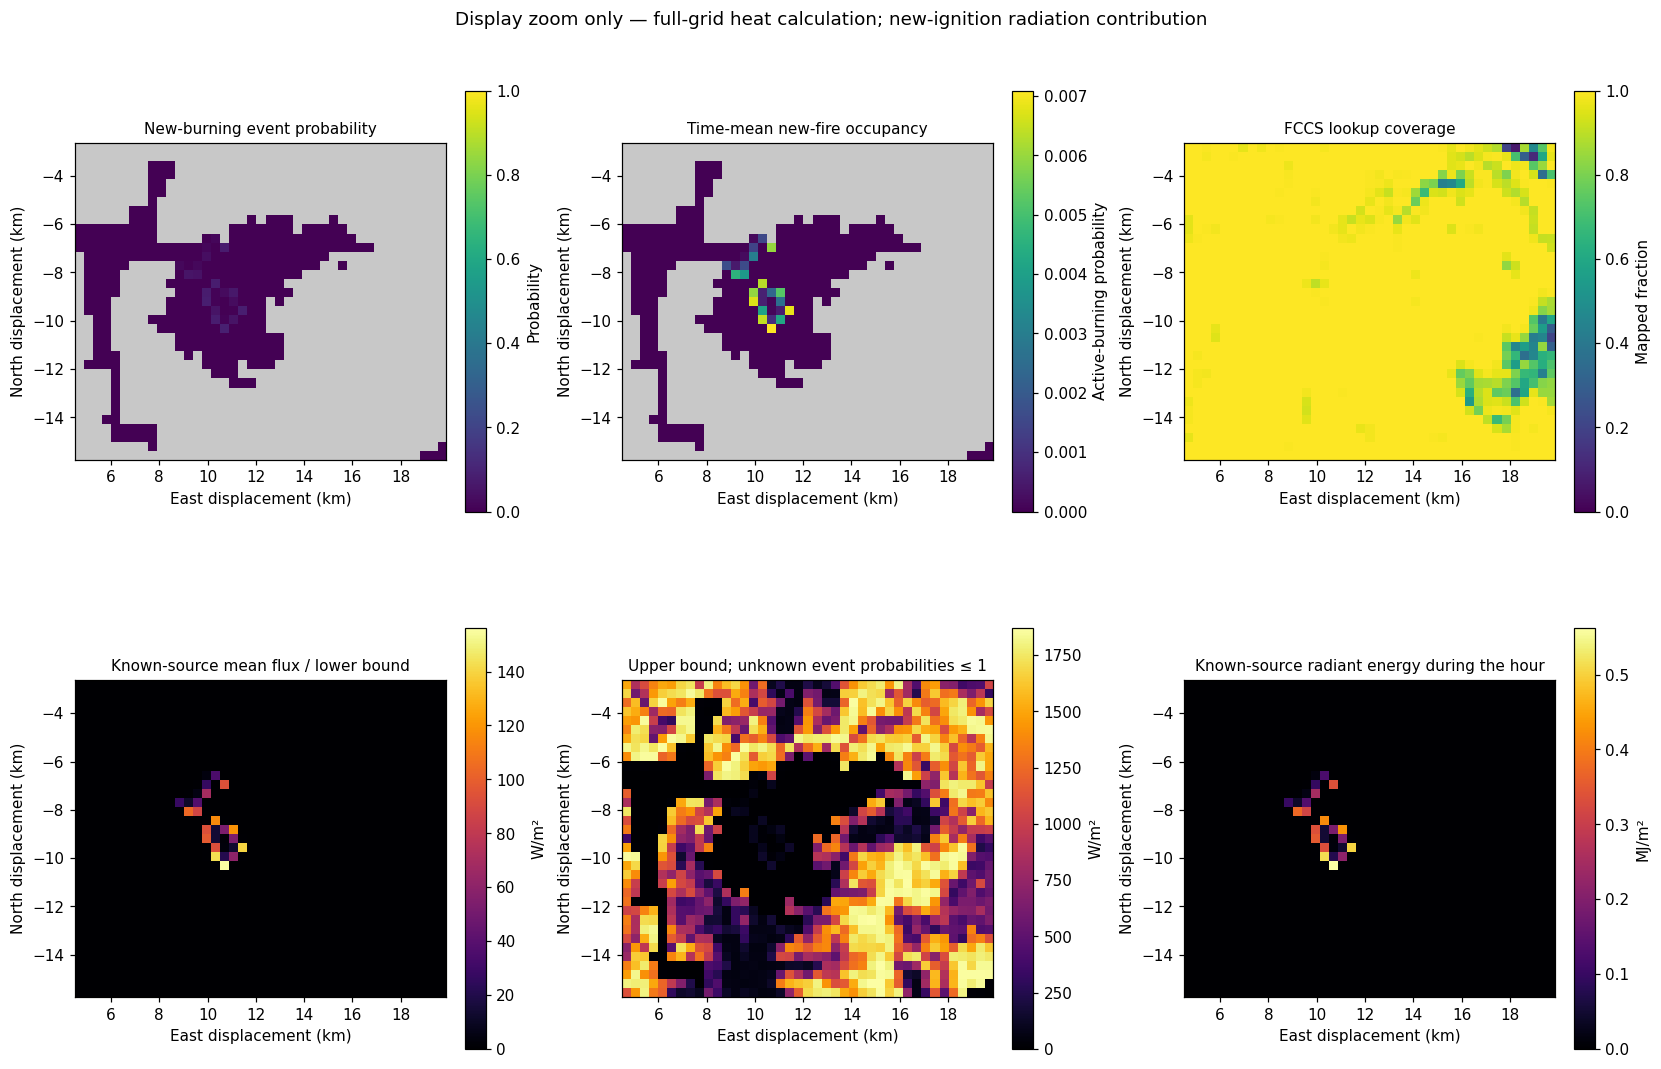

In [8]:
a, b, c, d, e, f = grid.transform
assert b == 0 and d == 0 and a > 0 and e < 0, "This event plotting helper expects a north-up metric grid."

def map_panel(ax, values, title, unit, cmap="viridis", vmin=None, vmax=None, crop=None):
    r0, r1, c0, c1 = crop or (0, shape[0], 0, shape[1])
    palette = plt.get_cmap(cmap).copy()
    palette.set_bad("#c8c8c8")
    image = ax.imshow(
        np.asarray(values)[r0:r1, c0:c1], origin="upper", interpolation="nearest",
        extent=(a*c0/1000, a*c1/1000, e*r1/1000, e*r0/1000),
        cmap=palette, vmin=vmin, vmax=vmax,
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("East displacement (km)")
    ax.set_ylabel("North displacement (km)")
    ax.figure.colorbar(image, ax=ax, label=unit, shrink=0.80)
    return image

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
map_panel(axes[0], np.where(current_burned_valid, current_burned, np.nan),
          "Retrospective cumulative burned state", "Burned indicator", vmin=0, vmax=1)
map_panel(axes[1], result.new_burn_probability,
          "Predicted new burning within next hour", "Probability", vmin=0, vmax=1)
map_panel(axes[2], fuel_load, "FCCS fuel with explicit unmapped fallback", "Dry fuel load (kg/m²)", cmap="YlGn", vmin=0)
fig.suptitle(f"{EVENT} — {CUTOFF_UTC}; gray probability cells are unknown")
fig.savefig(OUTPUT_DIR / "inputs_and_ecology.png", dpi=160)
plt.show()

fire_locations = np.argwhere(current_burned_valid & (current_burned > 0))
assert fire_locations.size, "Select a cutoff with some known burned area for this zoom."
margin = 8
crop = (
    max(0, int(fire_locations[:, 0].min()) - margin),
    min(shape[0], int(fire_locations[:, 0].max()) + margin + 1),
    max(0, int(fire_locations[:, 1].min()) - margin),
    min(shape[1], int(fire_locations[:, 1].max()) + margin + 1),
)
fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
map_panel(axes[0, 0], result.new_burn_probability, "New-burning event probability", "Probability", vmin=0, vmax=1, crop=crop)
map_panel(axes[0, 1], result.mean_active_burning_probability, "Time-mean new-fire occupancy", "Active-burning probability", vmin=0, crop=crop)
map_panel(axes[0, 2], ecology.coverage_fraction, "FCCS lookup coverage", "Mapped fraction", vmin=0, vmax=1, crop=crop)
map_panel(axes[1, 0], known_source_heat_spatial_matrix, "Known-source mean flux / lower bound", "W/m²", cmap="inferno", vmin=0, crop=crop)
map_panel(axes[1, 1], heat_upper_bound, "Upper bound; unknown event probabilities ≤ 1", "W/m²", cmap="inferno", vmin=0, crop=crop)
map_panel(axes[1, 2], result.incident_energy_lower_bound_j_m2 / 1e6,
          "Known-source radiant energy during the hour", "MJ/m²", cmap="inferno", vmin=0, crop=crop)
fig.suptitle("Display zoom only — full-grid heat calculation; new-ignition radiation contribution")
fig.savefig(OUTPUT_DIR / "known_source_heat_and_bounds.png", dpi=160)
plt.show()

## 7. Compare ecological and uniform fuel with identical probabilities

This comparison reuses the same forecast probability matrix and validity mask. Only the assumed fuel loading changes. Spatial reference loading changes source-strength specificity; the resulting numerical difference does **not** establish better accuracy against measured heat.

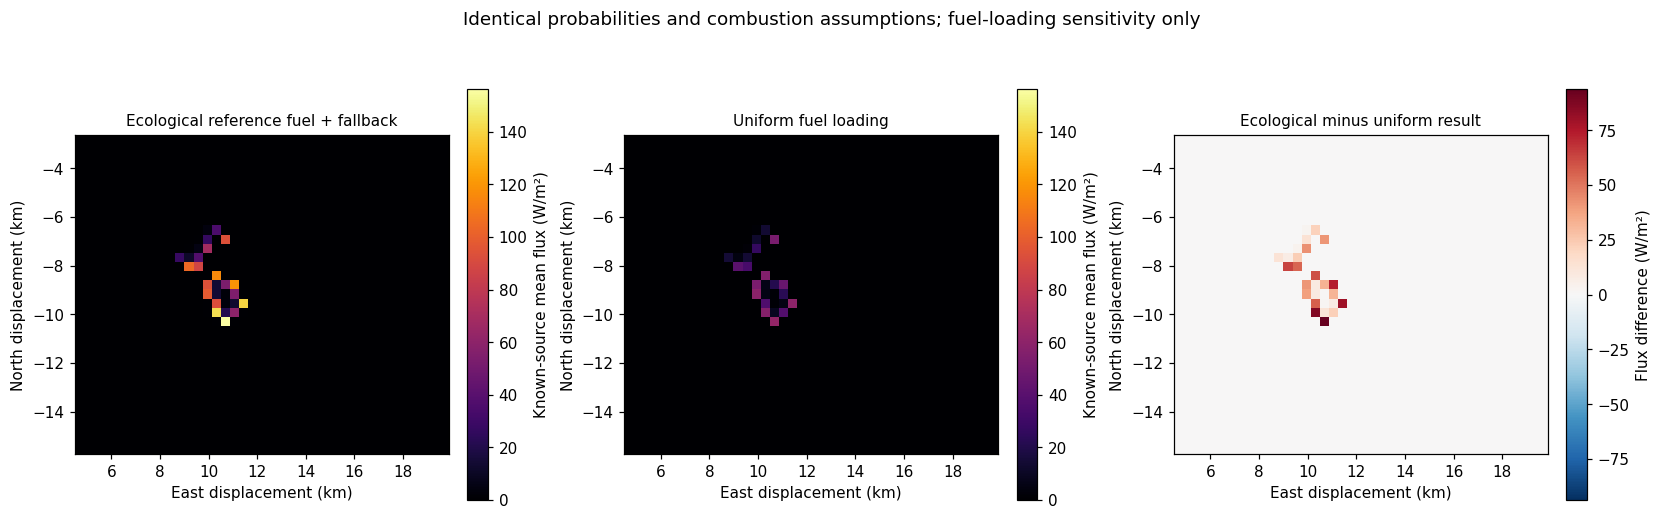

Ecological known-source peak (W/m²): 156.1772393559946
Uniform-fuel known-source peak (W/m²): 62.41479539135413
Maximum absolute difference (W/m²): 93.76244396464047


In [9]:
uniform_model = WildfireHeatModel(
    heat_model.predictor,
    grid=grid,
    combustion=CombustionParameters(
        fuel_load_kg_m2=UNMAPPED_FUEL_FALLBACK_KG_M2,
        heat_of_combustion_j_kg=HEAT_OF_COMBUSTION_J_KG,
        burning_duration_s=BURNING_DURATION_S,
        consumed_fraction=CONSUMED_FRACTION,
    ),
    radiative_fraction=RADIATIVE_FRACTION,
    emission_height_m=EMISSION_HEIGHT_M,
    receiver_height_m=RECEIVER_HEIGHT_M,
    atmospheric_transmissivity=ATMOSPHERIC_TRANSMISSIVITY,
    interval_s=INTERVAL_S,
)
uniform_result = uniform_model.predict_from_new_burn_probability_details(
    result.new_burn_probability, probability_valid=result.probability_valid,
)
np.testing.assert_allclose(uniform_result.new_burn_probability, result.new_burn_probability, equal_nan=True)
flux_difference = known_source_heat_spatial_matrix - uniform_result.known_source_heat_flux_w_m2
common_max = max(float(known_source_heat_spatial_matrix.max()), float(uniform_result.known_source_heat_flux_w_m2.max()))
difference_limit = max(float(np.abs(flux_difference).max()), 1e-12)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
map_panel(axes[0], known_source_heat_spatial_matrix, "Ecological reference fuel + fallback", "Known-source mean flux (W/m²)", cmap="inferno", vmin=0, vmax=common_max, crop=crop)
map_panel(axes[1], uniform_result.known_source_heat_flux_w_m2, "Uniform fuel loading", "Known-source mean flux (W/m²)", cmap="inferno", vmin=0, vmax=common_max, crop=crop)
map_panel(axes[2], flux_difference, "Ecological minus uniform result", "Flux difference (W/m²)", cmap="RdBu_r", vmin=-difference_limit, vmax=difference_limit, crop=crop)
fig.suptitle("Identical probabilities and combustion assumptions; fuel-loading sensitivity only")
fig.savefig(OUTPUT_DIR / "ecological_fuel_comparison.png", dpi=160)
plt.show()
print("Ecological known-source peak (W/m²):", float(known_source_heat_spatial_matrix.max()))
print("Uniform-fuel known-source peak (W/m²):", float(uniform_result.known_source_heat_flux_w_m2.max()))
print("Maximum absolute difference (W/m²):", float(np.abs(flux_difference).max()))

## 8. Demonstrate a fully identified expected-heat matrix

The following **synthetic** probability field is complete. It is supplied directly as next-hour new-burning probability, using the same explicit temporal bridge. It is separate from the saved predictor's real event result and supplies no replacement values for the real event's unknown cells.

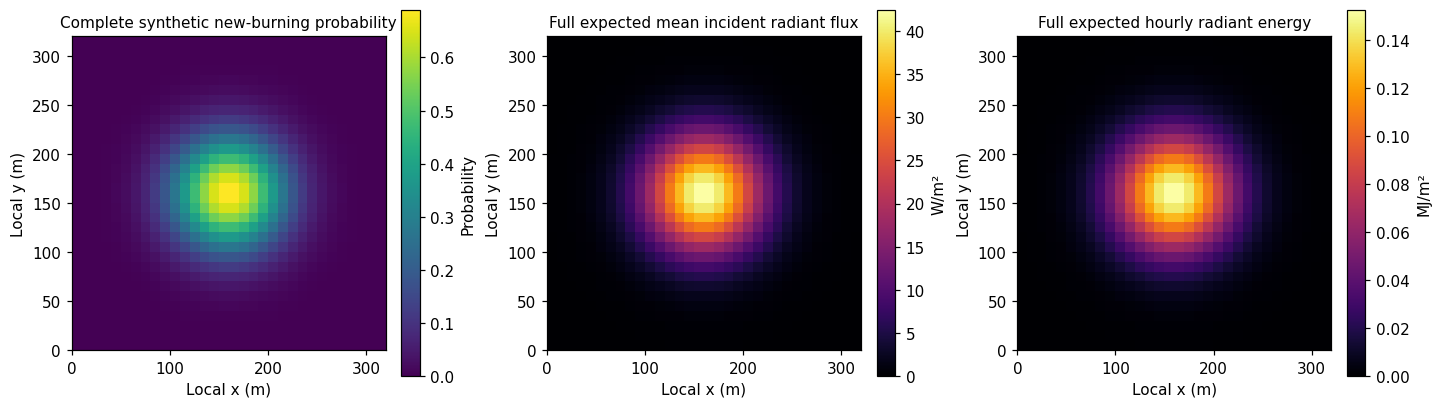

Complete synthetic expected-heat matrix: (32, 32)
Peak mean flux (W/m²): 42.39286043132844


In [10]:
synthetic_shape = (32, 32)
row, col = np.indices(synthetic_shape)
synthetic_q = 0.7 * np.exp(-((row - 15.5)**2 + (col - 15.5)**2) / (2 * 4.0**2))
synthetic_model = WildfireHeatModel(
    predictor=None,  # Direct-probability API does not invoke a trained predictor.
    grid=AffineGrid.from_cell_size(10.0),
    combustion=CombustionParameters(
        fuel_load_kg_m2=1.0,
        heat_of_combustion_j_kg=HEAT_OF_COMBUSTION_J_KG,
        burning_duration_s=BURNING_DURATION_S,
        consumed_fraction=CONSUMED_FRACTION,
    ),
    radiative_fraction=RADIATIVE_FRACTION,
    emission_height_m=EMISSION_HEIGHT_M,
    receiver_height_m=RECEIVER_HEIGHT_M,
    atmospheric_transmissivity=ATMOSPHERIC_TRANSMISSIVITY,
    interval_s=INTERVAL_S,
)
synthetic_result = synthetic_model.predict_from_new_burn_probability_details(synthetic_q)
synthetic_expected_heat_spatial_matrix = synthetic_result.expected_heat_flux_w_m2
assert synthetic_result.complete
assert synthetic_expected_heat_spatial_matrix.shape == synthetic_shape
assert np.isfinite(synthetic_expected_heat_spatial_matrix).all()
np.testing.assert_allclose(
    synthetic_result.expected_incident_energy_j_m2,
    synthetic_expected_heat_spatial_matrix * INTERVAL_S,
)
np.testing.assert_allclose(synthetic_result.heat_flux_lower_bound_w_m2, synthetic_result.heat_flux_upper_bound_w_m2)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, values, title, unit in zip(
    axes,
    (synthetic_q, synthetic_expected_heat_spatial_matrix, synthetic_result.expected_incident_energy_j_m2 / 1e6),
    ("Complete synthetic new-burning probability", "Full expected mean incident radiant flux", "Full expected hourly radiant energy"),
    ("Probability", "W/m²", "MJ/m²"),
):
    im = ax.imshow(values, origin="lower", extent=(0, 320, 0, 320), cmap="viridis" if unit == "Probability" else "inferno", vmin=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Local x (m)")
    ax.set_ylabel("Local y (m)")
    fig.colorbar(im, ax=ax, label=unit, shrink=0.85)
fig.savefig(OUTPUT_DIR / "complete_synthetic_heat.png", dpi=160)
plt.show()
print("Complete synthetic expected-heat matrix:", synthetic_expected_heat_spatial_matrix.shape)
print("Peak mean flux (W/m²):", float(synthetic_expected_heat_spatial_matrix.max()))

### Use an active-burning probability matrix directly

If your input already means **probability of active burning at a specified instant**, use `ExpectedHeatFluxModel.predict_details(p)` directly; do not apply the new-ignition temporal conversion again.

As a simple analytic verification, a 10 m × 10 m cell observed directly below its center with 5 m height separation subtends solid angle $\Omega=2\pi/3$, hence $K=1/6$. For $p=1$, fuel 1 kg/m², consumed fraction 1, $H_c=18$ MJ/kg, duration 60 s, $\chi=0.3$, and $\tau=1$, the expected incident flux is $0.3(18\times10^6/60)/6=15000$ W/m².

In [11]:
active_combustion = CombustionParameters(
    fuel_load_kg_m2=1.0, heat_of_combustion_j_kg=18_000_000.0,
    burning_duration_s=60.0, consumed_fraction=1.0,
)
active_model = ExpectedHeatFluxModel(
    grid=AffineGrid.from_cell_size(10.0),
    heat_release_rate_density_w_m2=active_combustion.heat_release_rate_density_w_m2,
    radiative_fraction=0.30, emission_height_m=5.0,
)
active_snapshot = active_model.predict_details(np.ones((1, 1)))
np.testing.assert_allclose(active_snapshot.incident_heat_flux_w_m2, [[15_000.0]], rtol=1e-12)
print("Analytic one-cell check (W/m²):", active_snapshot.incident_heat_flux_w_m2)

Analytic one-cell check (W/m²): [[15000.]]


## 9. Export matrices, masks, units, and provenance

The export stores real and synthetic results in separate compressed NumPy files. Real unknown values and coverage masks are preserved. Reload with `np.load(path, allow_pickle=False)`. The JSON records the saved checkpoint hash, channel contract, fuel reference provenance, explicit physical assumptions, and retrospective-data limitation. Figures are also saved as PNG files.

In [12]:
from dataclasses import fields
from datetime import datetime, timezone
import hashlib
import json

real_arrays = {
    field.name: getattr(result, field.name)
    for field in fields(result)
    if isinstance(getattr(result, field.name), np.ndarray)
}
real_arrays.update(
    fuel_loading_reference_mapped_mean_kg_m2=ecology.fuel_load_kg_m2,
    fuel_loading_with_explicit_fallback_kg_m2=fuel_load,
    fuel_loading_coverage_fraction=ecology.coverage_fraction,
    fuel_loading_strict_valid=ecology.valid,
    current_burned_area=current_burned,
    current_burned_area_valid=current_burned_valid,
    feature_valid=sample["feature_valid"][0].numpy(),
    uniform_known_source_heat_flux_w_m2=uniform_result.known_source_heat_flux_w_m2,
    ecological_minus_uniform_known_source_flux_w_m2=flux_difference,
    affine_transform=np.asarray(grid.transform),
    channel_names=np.asarray(contract["channels"], dtype="U"),
)
real_arrays_path = OUTPUT_DIR / "real_event_heat_arrays.npz"
np.savez_compressed(real_arrays_path, **real_arrays)
synthetic_arrays_path = OUTPUT_DIR / "complete_synthetic_heat_arrays.npz"
np.savez_compressed(
    synthetic_arrays_path,
    new_burn_probability=synthetic_q,
    mean_active_burning_probability=synthetic_result.mean_active_burning_probability,
    expected_heat_flux_w_m2=synthetic_expected_heat_spatial_matrix,
    expected_incident_energy_j_m2=synthetic_result.expected_incident_energy_j_m2,
    affine_transform=np.asarray(synthetic_model.heat_model.grid.transform),
)
arrival_surface = DATA_ROOT / "regions" / EVENT / "arrival_time_hours.tif"
summary = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "event": EVENT, "cutoff_utc": CUTOFF_UTC, "interval_s": INTERVAL_S,
    "shape": list(shape), "epsg": int(sample["epsg"]), "affine_transform": list(grid.transform),
    "runtime": {"python": sys.version.split()[0], "interpreter": sys.executable, "torch": torch.__version__, "device": DEVICE},
    "checkpoint": heat_model.predictor_provenance,
    "inference_input_keys": list(inference_keys),
    "environmental_intervals_end_by_cutoff": True,
    "current_state_arrival_surface": str(arrival_surface),
    "current_state_arrival_surface_sha256": hashlib.sha256(arrival_surface.read_bytes()).hexdigest(),
    "current_state_limitation": "Current burned state and validity are reconstructed from retrospective arrival/final-extent data; not operational forecast validation.",
    "ecological_reference": ecology.provenance,
    "fully_covered_fuel_cells": int(ecology.valid.sum()),
    "illustrative_physical_parameters": parameters,
    "conditional_ignition_time": "Uniform over the next 3600 s given new burning; constant emission for supplied duration",
    "scope": "Radiation from new ignitions only, within supplied grid; current active burning not supplied",
    "known_probability_cells": int(result.probability_valid.sum()),
    "unknown_probability_cells": int((~result.probability_valid).sum()),
    "real_full_expected_heat_available": bool(result.complete),
    "real_matrix_statistics": {name: matrix_statistics(value) for name, value in matrices.items()},
    "known_source_peak_flux_w_m2": float(known_source_heat_spatial_matrix.max()),
    "uniform_known_source_peak_flux_w_m2": float(uniform_result.known_source_heat_flux_w_m2.max()),
    "maximum_absolute_ecological_difference_w_m2": float(np.abs(flux_difference).max()),
    "comparison_interpretation": "Fuel-loading sensitivity, not demonstrated measured accuracy improvement",
    "synthetic_full_expected_heat_available": bool(synthetic_result.complete),
    "synthetic_shape": list(synthetic_shape),
    "synthetic_physical_parameters": {
        "fuel_load_kg_m2": 1.0, "heat_of_combustion_j_kg": HEAT_OF_COMBUSTION_J_KG,
        "burning_duration_s": BURNING_DURATION_S, "consumed_fraction": CONSUMED_FRACTION,
        "radiative_fraction": RADIATIVE_FRACTION, "emission_height_m": EMISSION_HEIGHT_M,
        "receiver_height_m": RECEIVER_HEIGHT_M, "atmospheric_transmissivity": ATMOSPHERIC_TRANSMISSIVITY,
        "cell_size_m": 10.0,
    },
    "synthetic_peak_mean_flux_w_m2": float(synthetic_expected_heat_spatial_matrix.max()),
    "units": {"heat_flux": "W/m²", "incident_energy_per_area": "J/m²", "fuel_loading": "kg/m²", "affine": "m"},
    "bound_scope": "Unknown source probabilities in [0,1], with fixed physical and conditional timing assumptions; no bound on model error or external fires",
    "pipeline_metadata": result.metadata,
}
summary_path = OUTPUT_DIR / "summary.json"
summary_path.write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n")

with np.load(real_arrays_path, allow_pickle=False) as reloaded:
    np.testing.assert_array_equal(reloaded["probability_valid"], result.probability_valid)
    np.testing.assert_allclose(reloaded['expected_heat_flux_w_m2'], expected_heat_spatial_matrix, equal_nan=True)
    np.testing.assert_allclose(reloaded["known_source_heat_flux_w_m2"], known_source_heat_spatial_matrix)
with np.load(synthetic_arrays_path, allow_pickle=False) as reloaded:
    assert np.isfinite(reloaded['expected_heat_flux_w_m2']).all()
print("Export round-trip checks passed.")
for artifact in sorted(OUTPUT_DIR.iterdir()):
    print(artifact.name)

Export round-trip checks passed.
complete_synthetic_heat.png
complete_synthetic_heat_arrays.npz
ecological_fuel_comparison.png
inputs_and_ecology.png
known_source_heat_and_bounds.png
real_event_heat_arrays.npz
summary.json


## Using the result in another Python program

For this notebook's real event, use `result.known_source_heat_flux_w_m2` together with the lower/upper bounds and validity information. Use `result.expected_heat_flux_w_m2` as a full expected spatial matrix only when `result.complete` is true. `result.expected_heat_flux_kw_m2` provides the corresponding kW/m² values.

This historical notebook deliberately supplies only the listed current-state/environment fields, so its calculation includes new ignition only. The maintained heat API now uses `arrival_hours`, `arrival_valid`, and `elapsed_hours` by default when those fields are supplied: existing burning persists only while its arrival age is below its configured duration. The [duration-aware heat example](../wildfire/examples.py) reads aligned FBFM40 fuel data to derive per-cell residence estimates and exports current/remaining/endpoint activity. These are reference-fuel and reconstructed-arrival scenarios, not measured per-cell extinction. Explicit `initial_active_burning_probability` and `initial_remaining_burning_duration_s` override sample arrival timing; `initial_burning_from_arrival=False` excludes it. Cumulative burned area alone cannot identify current activity.

The [README](../README.md#heat-guide) describes the public API and mathematical assumptions; [heat source references](../wildfire/heat_sources.json) records the internet physics sources; `heat/notebook_demo/summary.json` records this execution's provenance. The illustrative parameter values and ecological reference loading require event-specific justification before interpreting the magnitudes as measured wildfire exposure.